In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.85"
os.environ["HF_ENDPOINT"] = "https://hf-mirror.com"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import dataclasses

import jax

from openpi.models import model as _model
from openpi.policies import droid_policy
from openpi.policies import policy_config as _policy_config
from openpi.shared import download
from openpi.training import config as _config
from openpi.training import data_loader as _data_loader


libgomp: Invalid value for environment variable OMP_NUM_THREADS


# Policy inference

The following example shows how to create a policy from a checkpoint and run inference on a dummy example.

In [2]:
config = _config.get_config("pi0_fast_droid")
checkpoint_dir = "/root/autodl-tmp/openpi/dir/pi0_fast_droid"

print("开始加载 policy...")
policy = _policy_config.create_trained_policy(config, checkpoint_dir)
print("policy 加载成功")

开始加载 policy...
policy 加载成功


In [3]:
config = _config.get_config("pi0_fast_droid")
checkpoint_dir = "/root/autodl-tmp/openpi/dir/pi0_fast_droid"

print("开始加载 RTC policy...")

policy_rtc = _policy_config.create_trained_policy(
    config,
    checkpoint_dir,
    sample_kwargs={
        "generation_mode": "rtc",
        "rtc_chunk_size": 8,
        "max_decoding_steps": 256,
        "temperature": 0.0,
    },
)

print("RTC policy 加载成功")

开始加载 RTC policy...
RTC policy 加载成功


In [4]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["DATASETS_OFFLINE"] = "1"

from lerobot.common.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset(
    repo_id="droid_optimized",
    root="/root/autodl-tmp/openpi/droid_optimized",
    episodes=list(range(100)),
    # 不指定 video_backend，自动使用已修复的 torchcodec
)

print(dataset.features)

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

{'observation.images.exterior_image_1_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.images.exterior_image_2_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.images.wrist_image_left': {'dtype': 'video', 'shape': (180, 320, 3), 'names': ['height', 'width', 'channel'], 'video_info': {'video.fps': 15.0, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'has_audio': False}}, 'observation.state': {'dtype': 'float32', 'shape': (7,), 'names': {'motors': ['motor_0', 'motor_1', 'motor_2', 'motor_3', 'motor_4', 'motor_5', 'motor_6']}}, 'action': {'dtype': 'float32', 'shape': (7,), 'names': {'

In [5]:
import numpy as np
from openpi import transforms


class LeRobotToDroid(transforms.DataTransformFn):
    def __init__(
        self,
        model_state_dim: int = 8,
        gripper_dim: int = 1,
        default_gripper: float = 0.0,
    ):
        self.model_state_dim = model_state_dim
        self.gripper_dim = gripper_dim
        self.default_gripper = default_gripper

    def __call__(self, data: dict) -> dict:
        # 图像
        exterior = data["observation.images.exterior_image_1_left"]
        wrist = data["observation.images.wrist_image_left"]

        # state
        state = np.asarray(data["observation.state"], dtype=np.float32)
        if state.ndim == 0:
            state = state[np.newaxis]

        if state.shape[-1] < self.model_state_dim:
            pad_len = self.model_state_dim - state.shape[-1]
            # 只在最后一维补 gripper
            pad_width = [(0, 0)] * (state.ndim - 1) + [(0, pad_len)]
            state = np.pad(state, pad_width, constant_values=self.default_gripper)

        joint_dim = self.model_state_dim - self.gripper_dim
        joint = state[..., :joint_dim]
        gripper = state[..., joint_dim:]

        # prompt
        prompt = data["task"]

        return {
            "observation/exterior_image_1_left": exterior,
            "observation/wrist_image_left": wrist,
            "observation/joint_position": joint,
            "observation/gripper_position": gripper,
            "observation.state": state,
            "prompt": prompt,
        }


droid_inputs = LeRobotToDroid(model_state_dim=8, gripper_dim=1)

frame_idx = 100
sample = dataset[frame_idx]
droid_obs = droid_inputs(sample)


# import numpy as np

# for k, v in droid_obs.items():
#     if k == "prompt":
#         print(k, repr(v)); continue
#     v = np.asarray(v)
#     print(f"{k:40s} shape={v.shape} dtype={v.dtype} min={v.min():.3f} max={v.max():.3f}")

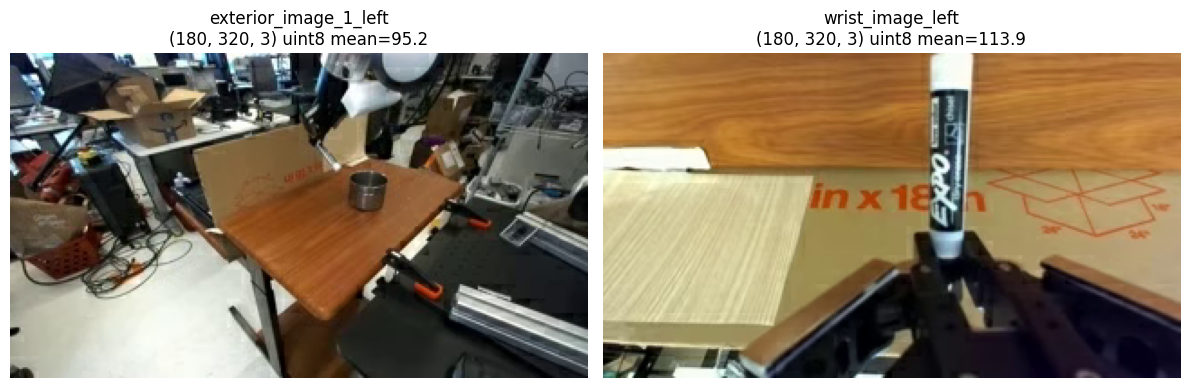

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def to_hwc_uint8(img):
    img = np.asarray(img)                      # torch tensor 先 .cpu().numpy()
    if img.ndim == 3 and img.shape[0] == 3:
        img = np.transpose(img, (1, 2, 0))     # CHW -> HWC
    if img.dtype != np.uint8:
        img = (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
    return img

keys = ["observation/exterior_image_1_left", "observation/wrist_image_left"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, keys):
    img = to_hwc_uint8(droid_obs[k])
    ax.imshow(img)
    ax.set_title(f"{k.split('/')[-1]}\n{img.shape} {img.dtype} mean={img.mean():.1f}")
    ax.axis("off")
plt.tight_layout()
plt.show()


In [7]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

# 1. 数据集路径
DATASET_DIR = Path("/root/autodl-tmp/openpi/droid_optimized")

# 2. 读取 episode 元数据
with open(DATASET_DIR / "meta/info.json", "r") as f:
    info = json.load(f)

print("Total episodes:", info["total_episodes"])
print("Total frames:", info["total_frames"])

# 3. 指定要对比的 episode
EPISODE_ID = 0

parquet_path = (
    DATASET_DIR
    / "data"
    / f"chunk-{EPISODE_ID // 1000:03d}"
    / f"episode_{EPISODE_ID:06d}.parquet"
)

episode_df = pd.read_parquet(parquet_path)

# 4. 提取该 episode 的 GT action
gt_acts_all = np.stack(
    episode_df["action"].to_numpy()
).astype(np.float64)

print("Episode:", EPISODE_ID)
print("GT action shape:", gt_acts_all.shape)
print("Number of frames:", len(gt_acts_all))
print("First 3 GT actions:\n", gt_acts_all[:3])

# 5. 选择预测对应的起始帧
GT_START_FRAME = 0

gt_acts = gt_acts_all[GT_START_FRAME:, :7]

print("\nGT ready for plotting")
print("gt_acts shape:", gt_acts.shape)
print("GT start frame:", GT_START_FRAME)

Total episodes: 100
Total frames: 32212
Episode: 0
GT action shape: (166, 7)
Number of frames: 166
First 3 GT actions:
 [[ 0.          0.          0.          0.          0.          0.
   1.        ]
 [ 0.          0.          0.          0.          0.          0.
   1.        ]
 [-0.01566741  0.0270242  -0.04648097 -0.01202362 -0.00146776 -0.02823568
   1.        ]]

GT ready for plotting
gt_acts shape: (166, 7)
GT start frame: 0


In [8]:
import inspect
import openpi

cls = type(policy._model)
fn = cls.sample_actions
names = lambda f: set(f.__code__.co_varnames) | set(f.__code__.co_cellvars)

print("openpi package   :", openpi.__file__)
print("model class      :", cls.__module__, cls.__qualname__)
print("sample_actions   :", inspect.getsourcefile(fn), "line", fn.__code__.co_firstlineno)
print("is pytorch model :", getattr(policy, "_is_pytorch_model", "n/a"))
print("Policy file      :", inspect.getsourcefile(type(policy)))
print("loaded sample_actions uses velocity_history:", "velocity_history" in names(fn))
print("loaded Policy.infer uses velocity_history  :", "velocity_history" in names(type(policy).infer))


openpi package   : /root/autodl-tmp/openpi/src/openpi/__init__.py
model class      : openpi.models.pi0_fast Pi0FAST
sample_actions   : /root/autodl-tmp/openpi/src/openpi/models/pi0_fast.py line 1044
is pytorch model : False
Policy file      : /root/autodl-tmp/openpi/src/openpi/policies/policy.py
loaded sample_actions uses velocity_history: False
loaded Policy.infer uses velocity_history  : False


In [9]:
# Run inference on a dummy example. This example corresponds to observations produced by the DROID runtime.
# example = droid_policy.make_droid_example()
# result = policy.infer(example)
result = policy.infer(droid_obs) # this is gt


# Delete the policy to free up memory.
# del policy

print("Actions shape:", result["actions"].shape)


result

Actions shape: (10, 8)


{'actions': array([[-0.2845851 , -0.2416712 , -0.0748675 , -0.08204417,  0.26918016,
         -0.14998927, -0.10930717, -0.00596324],
        [-0.29486132, -0.23144727, -0.08745871, -0.13198167,  0.30262482,
         -0.10647591, -0.11819401, -0.00596324],
        [-0.30816633, -0.21200021, -0.10728268, -0.20233647,  0.34510396,
         -0.04237625, -0.13165767, -0.00596324],
        [-0.31309874, -0.18523362, -0.12572297, -0.25549917,  0.36500402,
          0.01275169, -0.14281397, -0.00596324],
        [-0.29907672, -0.1537676 , -0.13429861, -0.2719239 ,  0.3450177 ,
          0.04264236, -0.1450046 , -0.00596324],
        [-0.26123133, -0.12068228, -0.12804421, -0.26100814,  0.29228085,
          0.05271033, -0.13457502, -0.00596324],
        [-0.20326712, -0.08921627, -0.107572  , -0.2493338 ,  0.23079576,
          0.06130576, -0.11254613, -0.00596324],
        [-0.13709957, -0.06244968, -0.07901188, -0.25703125,  0.18354939,
          0.08197725, -0.0845144 , -0.00596324],
     

In [10]:
result_rtc = policy.infer(droid_obs)

print("Actions shape:", result_rtc["actions"].shape)
print("RTC status:", result_rtc["policy_info"]["rtc"])

result_rtc

Actions shape: (10, 8)
RTC status: {'enabled': False, 'inference_timestamp': 1793277973.6927521, 'deadline_ms': None, 'deadline_missed': None}


{'actions': array([[-0.2845851 , -0.2416712 , -0.0748675 , -0.08204417,  0.26918016,
         -0.14998927, -0.10930717, -0.00596324],
        [-0.29486132, -0.23144727, -0.08745871, -0.13198167,  0.30262482,
         -0.10647591, -0.11819401, -0.00596324],
        [-0.30816633, -0.21200021, -0.10728268, -0.20233647,  0.34510396,
         -0.04237625, -0.13165767, -0.00596324],
        [-0.31309874, -0.18523362, -0.12572297, -0.25549917,  0.36500402,
          0.01275169, -0.14281397, -0.00596324],
        [-0.29907672, -0.1537676 , -0.13429861, -0.2719239 ,  0.3450177 ,
          0.04264236, -0.1450046 , -0.00596324],
        [-0.26123133, -0.12068228, -0.12804421, -0.26100814,  0.29228085,
          0.05271033, -0.13457502, -0.00596324],
        [-0.20326712, -0.08921627, -0.107572  , -0.2493338 ,  0.23079576,
          0.06130576, -0.11254613, -0.00596324],
        [-0.13709957, -0.06244968, -0.07901188, -0.25703125,  0.18354939,
          0.08197725, -0.0845144 , -0.00596324],
     

In [11]:
import numpy as np

import numpy as np

FPS = 15

def chunk_displacement(actions, mode="position", fps=15, state=None):
    """返回 (disp, net_disp)。disp: (N, D) 相对起点的累计位移;net_disp: (D,) 窗口净位移。"""
    a = np.asarray(actions, dtype=np.float64)
    if mode == "position":
        origin = a[0] if state is None else np.asarray(state, dtype=np.float64)
        disp = a - origin
    elif mode == "velocity":
        disp = np.cumsum(a / fps, axis=0)
    elif mode == "delta":
        disp = np.cumsum(a, axis=0)
    else:
        raise ValueError(f"unknown mode: {mode}")
    return disp, disp[-1]

def chunk_velocity(actions, fps=15, mode="position"):
    """返回 (vel, t_vel)。position 模式下 N 个点得到 N-1 个速度,时间取区间中点。"""
    a = np.asarray(actions, dtype=np.float64)
    dt = 1.0 / fps
    if mode == "position":
        vel = np.diff(a, axis=0) / dt
        t_vel = (np.arange(len(a) - 1) + 0.5) * dt
    elif mode == "velocity":
        vel = a
        t_vel = np.arange(len(a)) * dt
    elif mode == "delta":
        vel = a / dt
        t_vel = np.arange(len(a)) * dt
    else:
        raise ValueError(f"unknown mode: {mode}")
    return vel, t_vel

def chunk_acceleration(actions, fps=15, mode="position"):
    """返回 (acc, t_acc)。在速度上再做一次一阶差分,时间取相邻速度时刻的中点。"""
    dt = 1.0 / fps
    vel, t_vel = chunk_velocity(actions, fps=fps, mode=mode)
    acc = np.diff(vel, axis=0) / dt
    t_acc = (t_vel[:-1] + t_vel[1:]) / 2
    return acc, t_acc
    

# acts = np.asarray(result["actions"], dtype=np.float64)
# print("ptp:", np.ptp(acts[:, :7], axis=0))   # 应该非零

# disp, net = chunk_displacement(acts[:, :7], mode="position", fps=15)
# print("net disp:", net)

acts_default = np.asarray(result["actions"], dtype=np.float64)
acts_rtc = np.asarray(result_rtc["actions"], dtype=np.float64)

print("=== Default ===")
print("Actions shape:", acts_default.shape)
print("ptp:", np.ptp(acts_default[:, :7], axis=0))

disp_default, net_default = chunk_displacement(
    acts_default[:, :7], mode="position", fps=15
)
print("net disp:", net_default)

print("\n=== RTC ===")
print("Actions shape:", acts_rtc.shape)
print("ptp:", np.ptp(acts_rtc[:, :7], axis=0))

disp_rtc, net_rtc = chunk_displacement(
    acts_rtc[:, :7], mode="position", fps=15
)
print("net disp:", net_rtc)

print("\n=== Comparison ===")
print("Default net disp:", net_default)
print("RTC net disp:", net_rtc)
print("Difference:", np.asarray(net_rtc) - np.asarray(net_default))



=== Default ===
Actions shape: (10, 8)
ptp: [0.26746008 0.20889252 0.09891982 0.22171505 0.21417604 0.28382785
 0.10154726]
net disp: [ 0.23894644  0.20889252  0.03948871 -0.22171505 -0.11835218  0.28382785
  0.06584982]

=== RTC ===
Actions shape: (10, 8)
ptp: [0.26746008 0.20889252 0.09891982 0.22171505 0.21417604 0.28382785
 0.10154726]
net disp: [ 0.23894644  0.20889252  0.03948871 -0.22171505 -0.11835218  0.28382785
  0.06584982]

=== Comparison ===
Default net disp: [ 0.23894644  0.20889252  0.03948871 -0.22171505 -0.11835218  0.28382785
  0.06584982]
RTC net disp: [ 0.23894644  0.20889252  0.03948871 -0.22171505 -0.11835218  0.28382785
  0.06584982]
Difference: [0. 0. 0. 0. 0. 0. 0.]


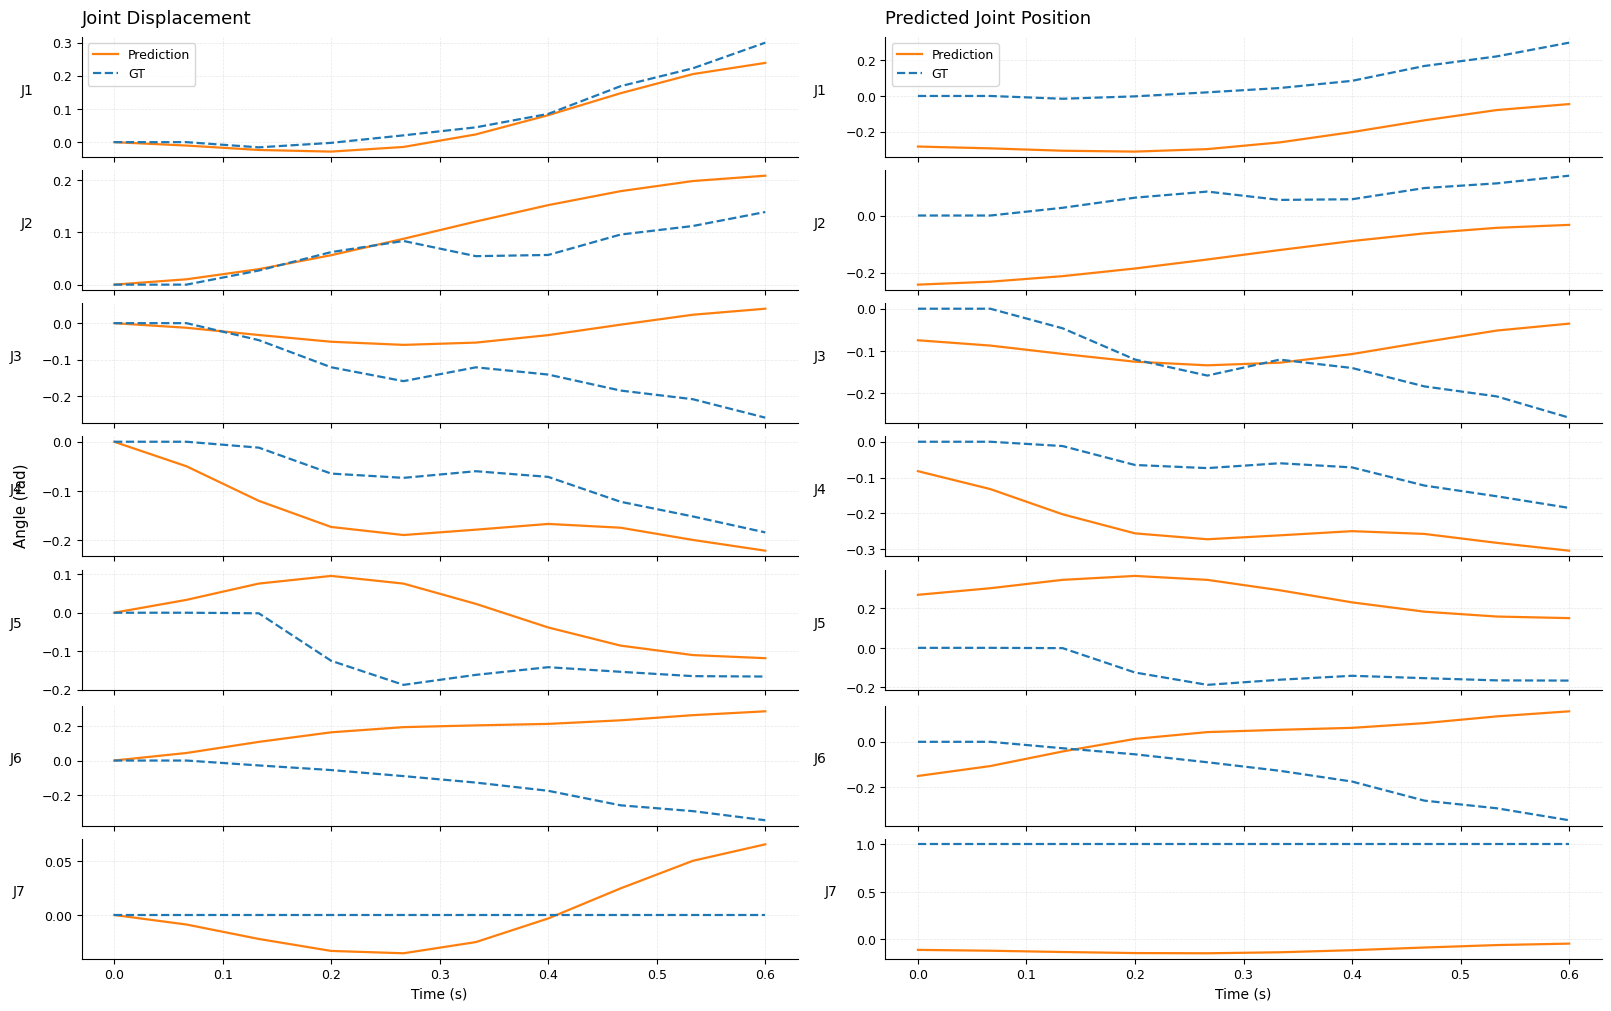

In [12]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15

# Prediction：沿用原来的数据处理
acts = np.asarray(result["actions"], dtype=np.float64)[:, :7]

# GT：使用前面独立 Cell 已经准备好的 gt_acts
gt_acts = np.asarray(gt_acts, dtype=np.float64)[:, :7]

# 对齐长度
n = min(len(acts), len(gt_acts))
acts = acts[:n]
gt_acts = gt_acts[:n]
t = np.arange(n) / FPS

# 累计位移：分别以各自的起点为零
pred_disp = acts - acts[0]
gt_disp = gt_acts - gt_acts[0]

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
})

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

for j in range(7):
    # 左列：Joint Displacement
    ax = axes[j, 0]

    ax.plot(
        t, pred_disp[:, j],
        color="tab:orange",
        linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t, gt_disp[:, j],
        color="tab:blue",
        linestyle="--",
        linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：原始数值对比
    ax = axes[j, 1]

    ax.plot(
        t, acts[:, j],
        color="tab:orange",
        linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t, gt_acts[:, j],
        color="tab:blue",
        linestyle="--",
        linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# 标题
axes[0, 0].set_title("Joint Displacement", loc="left", pad=10)
axes[0, 1].set_title("Predicted Joint Position", loc="left", pad=10)

# 图例只显示一次
axes[0, 0].legend(loc="best")
axes[0, 1].legend(loc="best")

# 横轴
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel("Angle (rad)", x=0.005)

# 保存并显示
fig.savefig(
    "joint_tracking_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

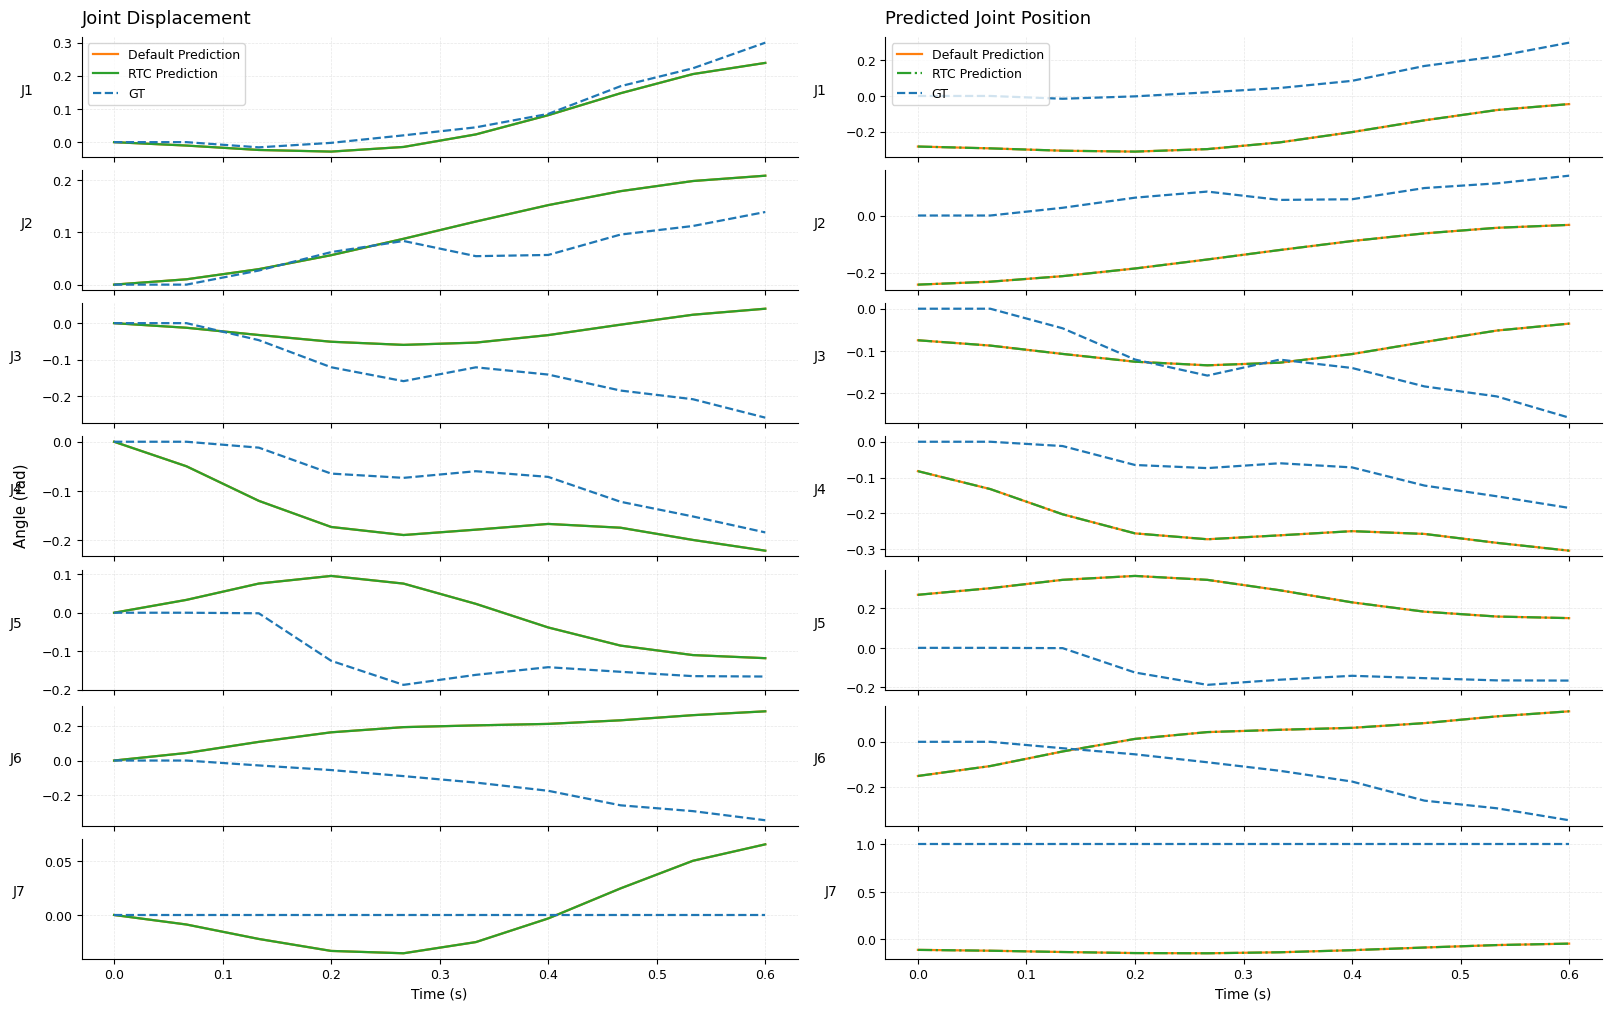

In [13]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15

# Default Prediction
acts = np.asarray(result["actions"], dtype=np.float64)[:, :7]

# RTC Prediction
acts_rtc = np.asarray(result_rtc["actions"], dtype=np.float64)[:, :7]

# Ground Truth
gt_acts = np.asarray(gt_acts, dtype=np.float64)[:, :7]

# 对齐长度
n = min(len(acts), len(acts_rtc), len(gt_acts))
acts = acts[:n]
acts_rtc = acts_rtc[:n]
gt_acts = gt_acts[:n]

t = np.arange(n) / FPS

# 累计位移：分别以各自的起点为零
pred_disp = acts - acts[0]
rtc_disp = acts_rtc - acts_rtc[0]
gt_disp = gt_acts - gt_acts[0]

plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
})

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 10),
    sharex="col",
    constrained_layout=True
)

for j in range(7):
    # 左列：Joint Displacement
    ax = axes[j, 0]

    ax.plot(
        t, pred_disp[:, j],
        color="tab:orange",
        linewidth=1.6,
        label="Default Prediction"
    )
    ax.plot(
        t, rtc_disp[:, j],
        color="tab:green",
        linestyle="-.",
        linewidth=1.6,
        label="RTC Prediction"
    )
    ax.plot(
        t, gt_disp[:, j],
        color="tab:blue",
        linestyle="--",
        linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：原始关节位置数值对比
    ax = axes[j, 1]

    ax.plot(
        t, acts[:, j],
        color="tab:orange",
        linewidth=1.6,
        label="Default Prediction"
    )
    ax.plot(
        t, acts_rtc[:, j],
        color="tab:green",
        linestyle="-.",
        linewidth=1.6,
        label="RTC Prediction"
    )
    ax.plot(
        t, gt_acts[:, j],
        color="tab:blue",
        linestyle="--",
        linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# 标题
axes[0, 0].set_title("Joint Displacement", loc="left", pad=10)
axes[0, 1].set_title("Predicted Joint Position", loc="left", pad=10)

# 图例只显示一次
axes[0, 0].legend(loc="best")
axes[0, 1].legend(loc="best")

# 横轴
axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel("Angle (rad)", x=0.005)

# 保存并显示
fig.savefig(
    "joint_tracking_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [14]:
print("Default shape:", np.asarray(result["actions"]).shape)
print("RTC shape:", np.asarray(result_rtc["actions"]).shape)

acts_default = np.asarray(result["actions"], dtype=np.float64)
acts_rtc = np.asarray(result_rtc["actions"], dtype=np.float64)

print("Default range:", acts_default.min(), acts_default.max())
print("RTC range:", acts_rtc.min(), acts_rtc.max())
print("Max absolute difference:",
      np.max(np.abs(acts_default - acts_rtc)))

Default shape: (10, 8)
RTC shape: (10, 8)
Default range: -0.3130987408414013 0.3650040168214166
RTC range: -0.3130987408414013 0.3650040168214166
Max absolute difference: 0.0


In [15]:
import inspect

print("=== Policy config ===")
print("mode:", policy._generation_mode)
print("chunk size:", policy._rtc_chunk_size)
print("RTC supported:", policy._rtc_supported)

print("\n=== Model sample_actions signature ===")
print(inspect.signature(policy._model.sample_actions))

print("\n=== Returned metadata ===")
print(result_rtc["policy_info"]["generation_config"])
print(result_rtc["policy_info"]["rtc"])

=== Policy config ===
mode: default
chunk size: 8
RTC supported: True

=== Model sample_actions signature ===
(rng: Union[jax.Array, numpy.ndarray, numpy.bool_, numpy.number, bool, int, float, complex], observation: openpi.models.model.Observation, *, max_decoding_steps: Union[int, jaxtyping.Int[Array, ''], jaxtyping.Int[Tensor, '']] = 256, temperature: float = 0.0, generation_mode: Optional[Literal['default', 'rtc']] = None, rtc_chunk_size: int | None = None) -> Union[jaxtyping.Float[Array, '*b ah ad'], jaxtyping.Float[Tensor, '*b ah ad'], jaxtyping.Float[ndarray, '*b ah ad']]

=== Returned metadata ===
{'generation_mode': 'default', 'max_decoding_steps': 256, 'temperature': 0.0, 'rtc_chunk_size': None}
{'enabled': False, 'inference_timestamp': 1793277973.6927521, 'deadline_ms': None, 'deadline_missed': None}


In [16]:
# print("Mode:", policy_rtc._generation_mode)
# print("Chunk size:", policy_rtc._rtc_chunk_size)
# print("RTC supported:", policy_rtc._rtc_supported)

# result_rtc = policy_rtc.infer(droid_obs)

# print("Generation config:",
#       result_rtc["policy_info"]["generation_config"])
# print("RTC status:",
#       result_rtc["policy_info"]["rtc"])

Prediction max |vel|: [0.9925 0.4963 0.4284 1.0553 0.9223 0.9615 0.4205]
RTC max |vel|: [0.9925 0.4963 0.4284 1.0553 0.9223 0.9615 0.4205 0.    ]
GT max |vel|: [1.2542 0.587  1.1118 0.7922 1.8554 1.2565 0.    ]


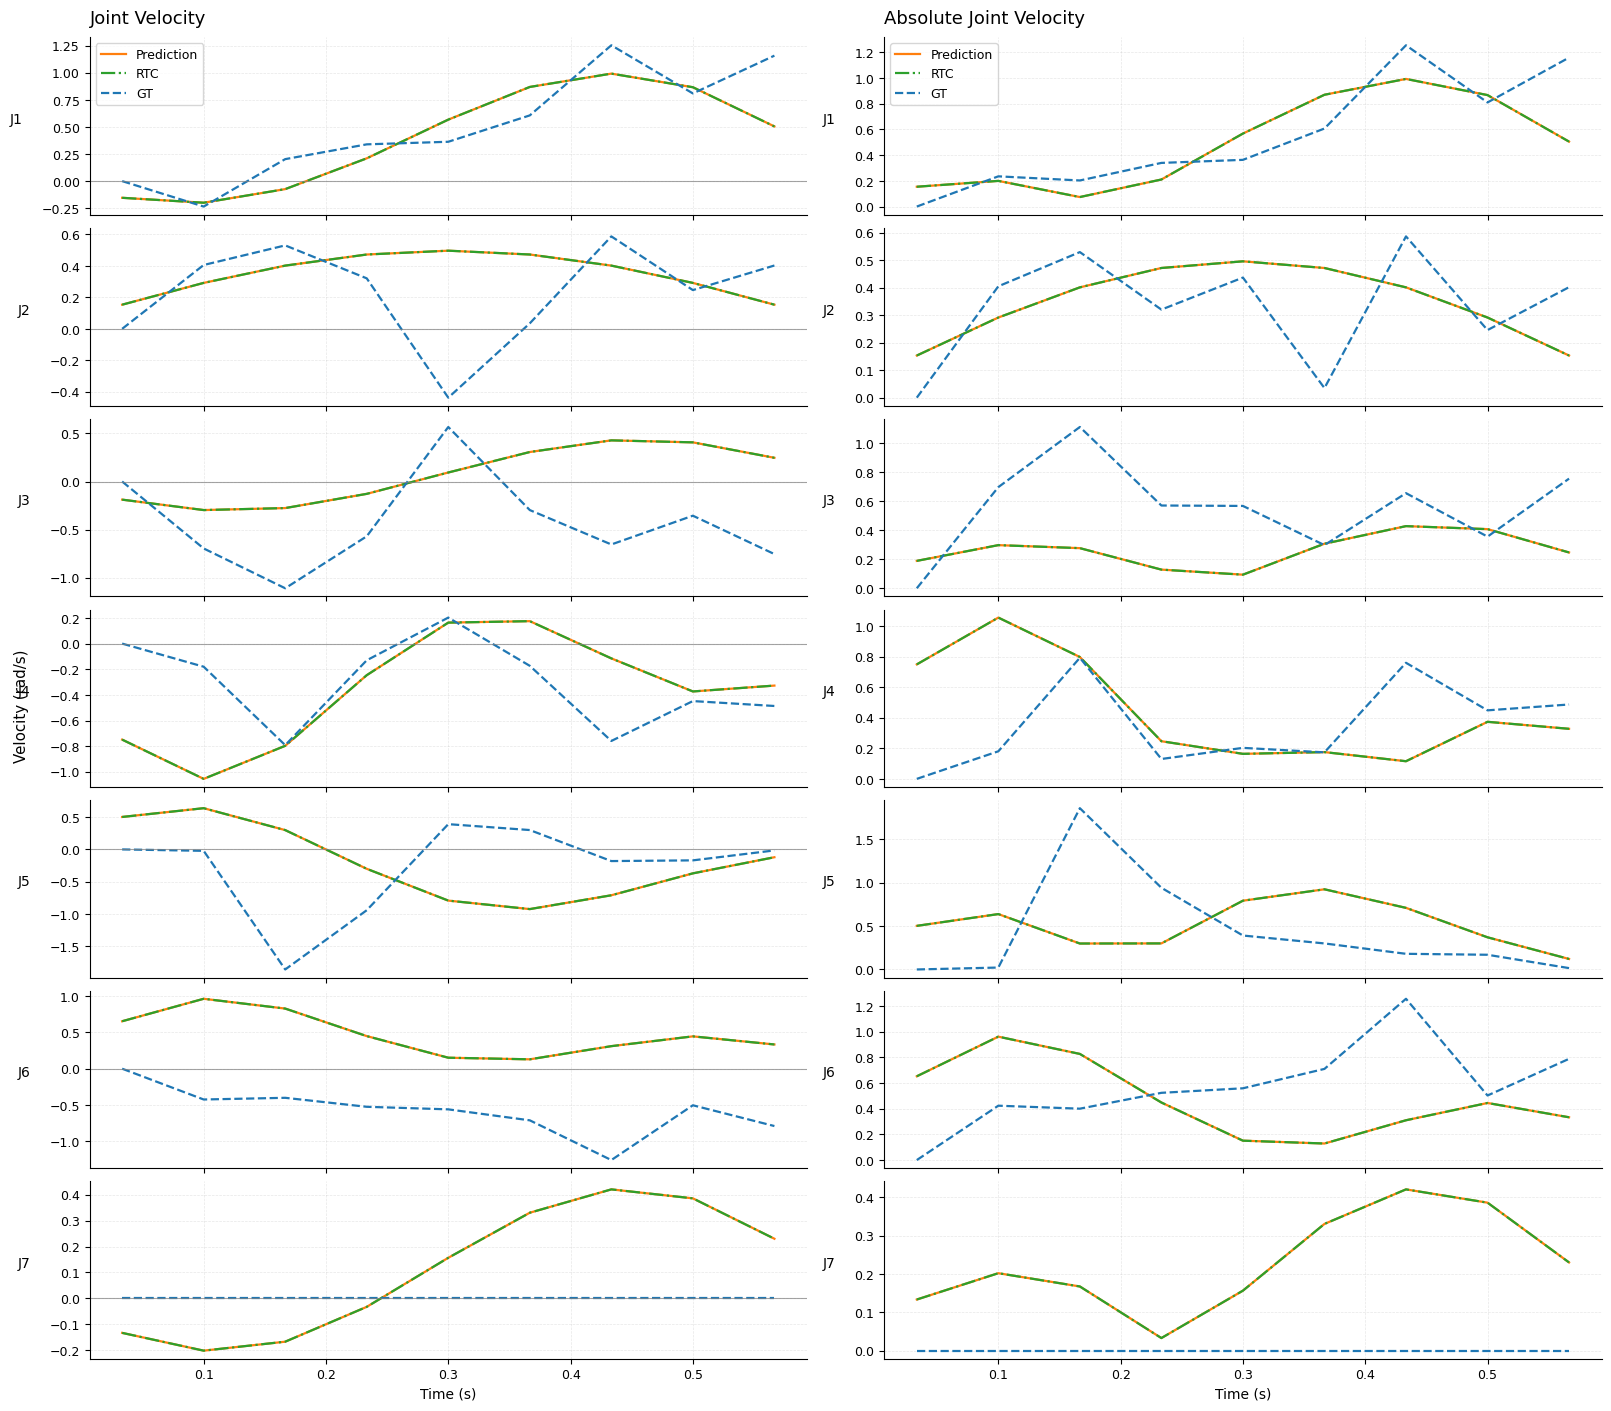

In [17]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15

# RTC 预测动作
rtc_acts = np.asarray(result_rtc["actions"])
if rtc_acts.ndim == 3:
    rtc_acts = rtc_acts[0]

# Prediction 和 GT 使用相同的速度计算方法
vel, t_vel = chunk_velocity(acts, fps=FPS, mode="position")
rtc_vel, t_rtc_vel = chunk_velocity(
    rtc_acts, fps=FPS, mode="position"
)
gt_vel, t_gt_vel = chunk_velocity(gt_acts, fps=FPS, mode="position")

# 对齐长度
n = min(
    len(vel), len(rtc_vel), len(gt_vel),
    len(t_vel), len(t_rtc_vel), len(t_gt_vel)
)

vel = vel[:n]
rtc_vel = rtc_vel[:n]
gt_vel = gt_vel[:n]
t_vel = t_vel[:n]

np.set_printoptions(precision=4, suppress=True)
print("Prediction max |vel|:", np.abs(vel).max(axis=0))
print("RTC max |vel|:", np.abs(rtc_vel).max(axis=0))
print("GT max |vel|:", np.abs(gt_vel).max(axis=0))

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 14),
    sharex="col",
    constrained_layout=True
)

for j in range(vel.shape[1]):
    # 左列：带方向的关节速度
    ax = axes[j, 0]

    ax.plot(
        t_vel, vel[:, j],
        color="tab:orange", linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t_vel, rtc_vel[:, j],
        color="tab:green", linestyle="-.", linewidth=1.6,
        label="RTC"
    )
    ax.plot(
        t_vel, gt_vel[:, j],
        color="tab:blue", linestyle="--", linewidth=1.6,
        label="GT"
    )

    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：关节速度绝对值
    ax = axes[j, 1]

    ax.plot(
        t_vel, np.abs(vel[:, j]),
        color="tab:orange", linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t_vel, np.abs(rtc_vel[:, j]),
        color="tab:green", linestyle="-.", linewidth=1.6,
        label="RTC"
    )
    ax.plot(
        t_vel, np.abs(gt_vel[:, j]),
        color="tab:blue", linestyle="--", linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_title("Joint Velocity", loc="left", pad=10)
axes[0, 1].set_title("Absolute Joint Velocity", loc="left", pad=10)

axes[0, 0].legend(loc="best")
axes[0, 1].legend(loc="best")

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel("Velocity (rad/s)", x=0.005)
fig.savefig(
    "joint_velocity_comparison_rtc.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Prediction acc shape: (8, 7)
Prediction max |acc|: [5.429 2.075 3.337 8.266 8.974 5.678 2.84 ]
RTC max |acc|: [5.429 2.075 3.337 8.266 8.974 5.678 2.84  0.   ]
GT max |acc|: [ 9.71  11.365 17.072  9.931 27.501 11.302  0.   ]


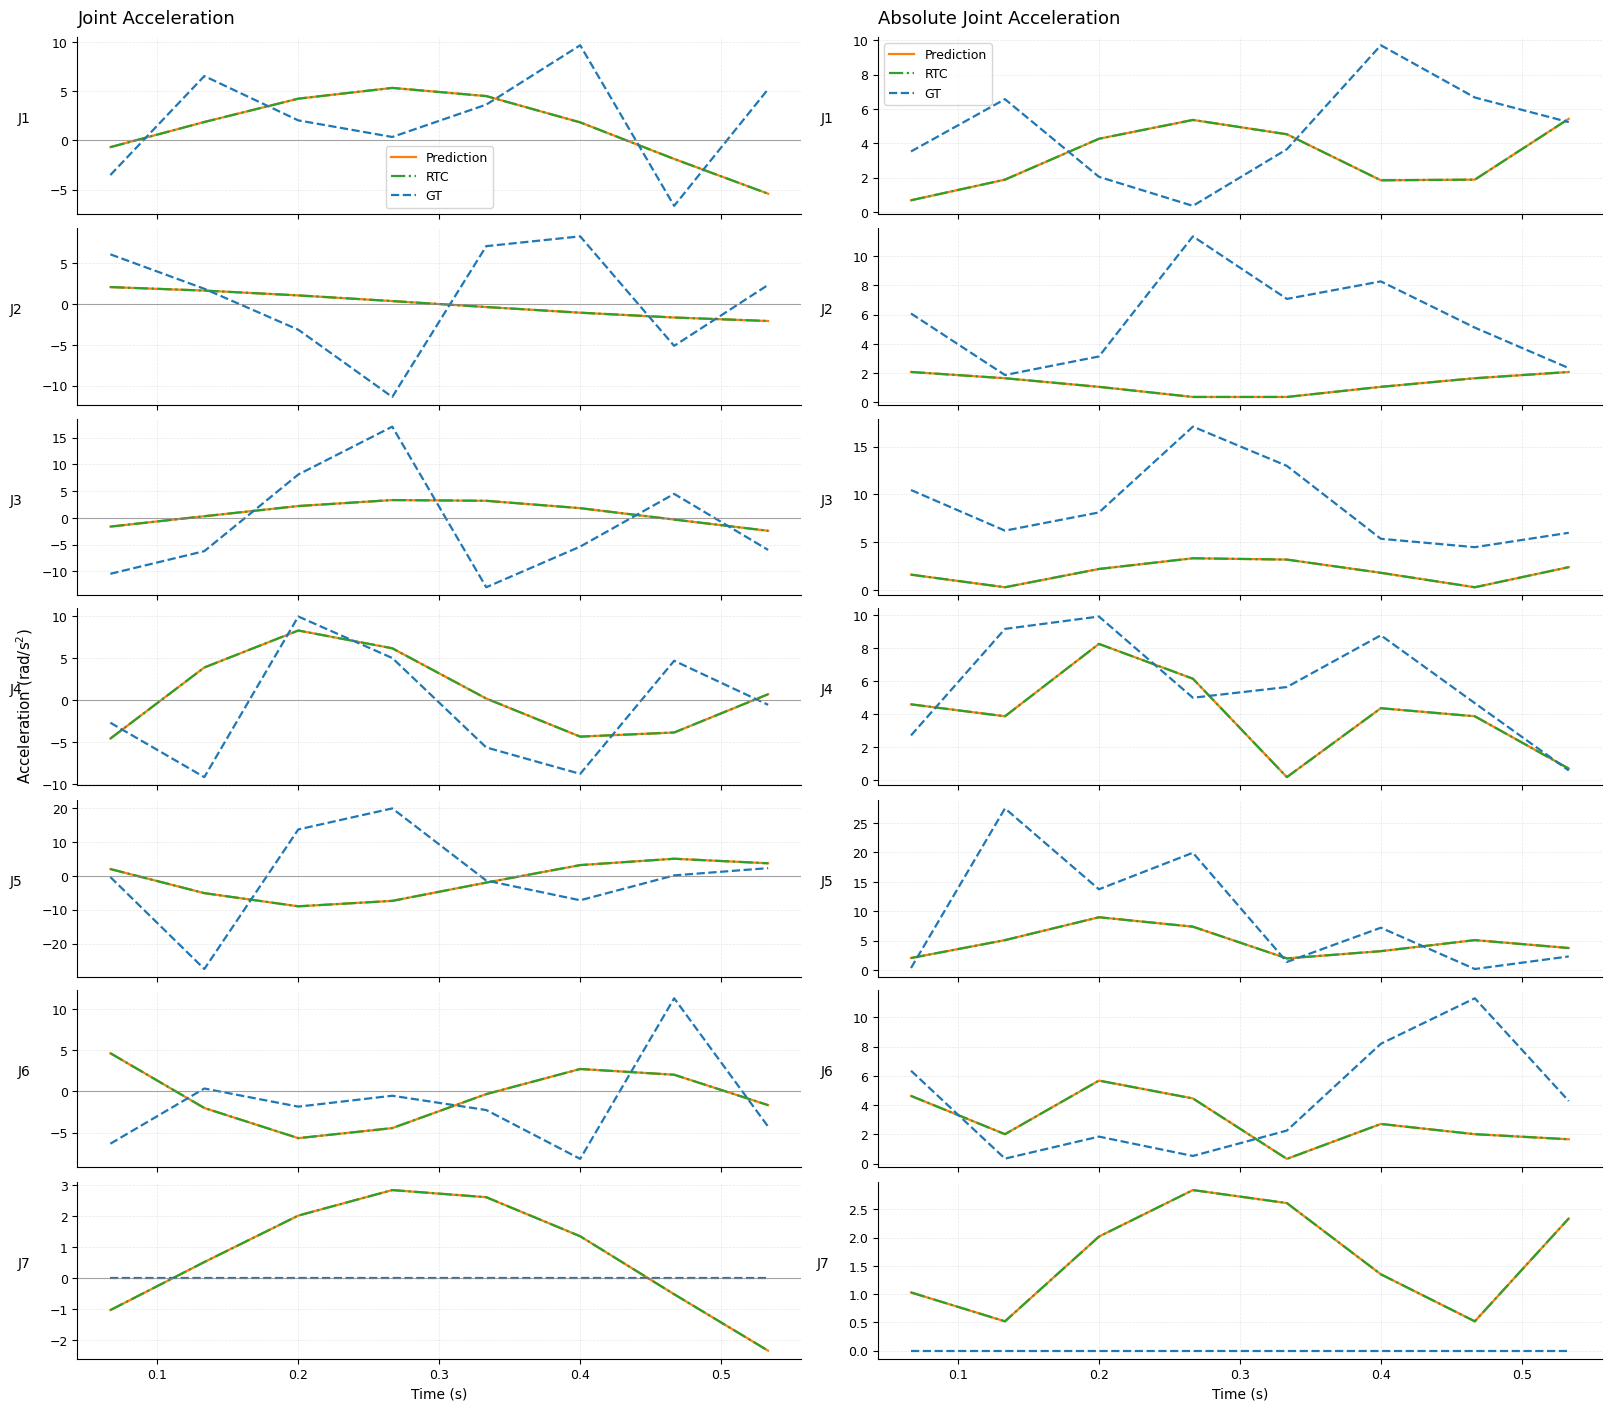

In [18]:
import numpy as np
import matplotlib.pyplot as plt

FPS = 15

# RTC 预测动作
rtc_acts = np.asarray(result_rtc["actions"])
if rtc_acts.ndim == 3:
    rtc_acts = rtc_acts[0]

# 分别计算 Prediction、RTC 和 GT 加速度
acc, t_acc = chunk_acceleration(acts, fps=FPS, mode="position")
rtc_acc, t_rtc_acc = chunk_acceleration(
    rtc_acts, fps=FPS, mode="position"
)
gt_acc, t_gt_acc = chunk_acceleration(
    gt_acts, fps=FPS, mode="position"
)

# 对齐长度
n = min(
    len(acc), len(rtc_acc), len(gt_acc),
    len(t_acc), len(t_rtc_acc), len(t_gt_acc)
)

acc = acc[:n]
rtc_acc = rtc_acc[:n]
gt_acc = gt_acc[:n]
t_acc = t_acc[:n]

np.set_printoptions(precision=3, suppress=True)
print("Prediction acc shape:", acc.shape)
print("Prediction max |acc|:", np.abs(acc).max(axis=0))
print("RTC max |acc|:", np.abs(rtc_acc).max(axis=0))
print("GT max |acc|:", np.abs(gt_acc).max(axis=0))

fig, axes = plt.subplots(
    7, 2,
    figsize=(16, 14),
    sharex="col",
    constrained_layout=True
)

for j in range(acc.shape[1]):
    # 左列：带方向的关节加速度
    ax = axes[j, 0]

    ax.plot(
        t_acc, acc[:, j],
        color="tab:orange", linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t_acc, rtc_acc[:, j],
        color="tab:green", linestyle="-.", linewidth=1.6,
        label="RTC"
    )
    ax.plot(
        t_acc, gt_acc[:, j],
        color="tab:blue", linestyle="--", linewidth=1.6,
        label="GT"
    )

    ax.axhline(0, color="gray", linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # 右列：加速度绝对值
    ax = axes[j, 1]

    ax.plot(
        t_acc, np.abs(acc[:, j]),
        color="tab:orange", linewidth=1.6,
        label="Prediction"
    )
    ax.plot(
        t_acc, np.abs(rtc_acc[:, j]),
        color="tab:green", linestyle="-.", linewidth=1.6,
        label="RTC"
    )
    ax.plot(
        t_acc, np.abs(gt_acc[:, j]),
        color="tab:blue", linestyle="--", linewidth=1.6,
        label="GT"
    )

    ax.set_ylabel(f"J{j+1}", rotation=0, labelpad=18)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0, 0].set_title("Joint Acceleration", loc="left", pad=10)
axes[0, 1].set_title("Absolute Joint Acceleration", loc="left", pad=10)

axes[0, 0].legend(loc="best")
axes[0, 1].legend(loc="best")

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.supylabel(r"Acceleration (rad/s$^2$)", x=0.005)
fig.savefig(
    "joint_acceleration_comparison_rtc.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [19]:
import numpy as np

pred = np.asarray(acts)
rtc = np.asarray(rtc_acts)
gt = np.asarray(gt_acts)

# 对齐形状
n = min(len(pred), len(rtc), len(gt))
pred = pred[:n]
rtc = rtc[:n]
gt = gt[:n]

print("Window duration:", n / FPS, "seconds")

print("\nPrediction vs GT")
print("MAE:", np.mean(np.abs(pred - gt)))
print("Max abs error:", np.max(np.abs(pred - gt)))

print("\nRTC vs Prediction")
print("MAE:", np.mean(np.abs(rtc[..., :7] - pred)))
print("Max abs difference:", np.max(np.abs(rtc[..., :7] - pred)))

print("\nRTC vs GT")
print("MAE:", np.mean(np.abs(rtc[..., :7] - gt)))
print("Max abs error:", np.max(np.abs(rtc[..., :7] - gt)))

Window duration: 0.6666666666666666 seconds

Prediction vs GT
MAE: 0.347486571249749
Max abs error: 1.1450046043954694

RTC vs Prediction


ValueError: operands could not be broadcast together with shapes (10,8) (10,7) 

In [20]:
# print("Prediction shape:", np.asarray(acts).shape)
# print("RTC shape:", np.asarray(rtc_acts).shape)
# print("GT shape:", np.asarray(gt_acts).shape)

# print("Prediction:", np.asarray(acts)[0])
# print("RTC:", np.asarray(rtc_acts)[0])
# print("GT:", np.asarray(gt_acts)[0])

Prediction shape: (10, 7)
RTC shape: (10, 8)
GT shape: (10, 7)
Prediction: [-0.285 -0.242 -0.075 -0.082  0.269 -0.15  -0.109]
RTC: [-0.285 -0.242 -0.075 -0.082  0.269 -0.15  -0.109 -0.006]
GT: [0. 0. 0. 0. 0. 0. 1.]


In [25]:
# print("\nRTC vs Prediction")
# print("MAE:", np.mean(np.abs(rtc[..., :7] - pred)))
# print("Max abs difference:", np.max(np.abs(rtc[..., :7] - pred)))

# print("\nRTC vs GT")
# print("MAE:", np.mean(np.abs(rtc[..., :7] - gt)))
# print("Max abs error:", np.max(np.abs(rtc[..., :7] - gt)))


RTC vs Prediction
MAE: 0.0
Max abs difference: 0.0

RTC vs GT
MAE: 0.347486571249749
Max abs error: 1.1450046043954694


In [ ]:
# 滑动窗口

import time
import numpy as np

FPS = 15
START, END, STRIDE = 10, 1000, 1   # 下标范围和步长。stride=1 约 990 次推理

records = []
chunks = {}   # idx -> (10, 7) 原始动作块,方便之后拼接或融合

t0 = time.time()
for idx in range(START, END, STRIDE):
    sample = dataset[idx]
    droid_obs = droid_inputs(sample)
    result = policy.infer(droid_obs)

    acts = np.asarray(result["actions"], dtype=np.float64)[:, :7]   # 只取前 7 维,去掉夹爪
    disp, net = chunk_displacement(acts, mode="position", fps=FPS)
    vel, t_vel = chunk_velocity(acts, fps=FPS, mode="position")
    acc, t_acc = chunk_acceleration(acts, fps=FPS, mode="position")

    chunks[idx] = acts
    records.append({
        "idx": idx,
        "episode": int(sample["episode_index"]) if "episode_index" in sample else -1,
        "state": np.asarray(sample["observation.state"], dtype=np.float64),
        "net_disp": net,
        "path_len": np.abs(np.diff(acts, axis=0)).sum(axis=0),
        "max_vel": np.abs(vel).max(axis=0),
        "max_acc": np.abs(acc).max(axis=0),
        "const": bool(np.ptp(acts, axis=0).max() == 0),
        "infer_ms": result["policy_timing"]["infer_ms"],
    })

# 汇总成数组,第一维是推理次数 M
idxs     = np.array([r["idx"] for r in records])
episodes = np.array([r["episode"] for r in records])
states   = np.stack([r["state"] for r in records])
net_disp = np.stack([r["net_disp"] for r in records])    # (M, 7)
path_len = np.stack([r["path_len"] for r in records])    # (M, 7)
max_vel  = np.stack([r["max_vel"] for r in records])     # (M, 7)
max_acc  = np.stack([r["max_acc"] for r in records])     # (M, 7)
is_const = np.array([r["const"] for r in records])
infer_ms = np.array([r["infer_ms"] for r in records])

# 检查
n_unique_state = len({s.tobytes() for s in states})
print(f"推理 {len(records)} 次,用时 {time.time() - t0:.0f}s,平均 infer {infer_ms.mean():.0f} ms")
print(f"涉及 episode: {np.unique(episodes)}")
print(f"不同的 state 数: {n_unique_state} / {len(records)}")
print(f"常量块数量: {is_const.sum()}")
if n_unique_state == 1:
    print("警告: 所有样本的 state 相同,droid_inputs 可能没有用到 sample")

np.set_printoptions(precision=3, suppress=True)
print("max|vel| 全程最大:", max_vel.max(axis=0))
print("max|acc| 全程最大:", max_acc.max(axis=0))


In [ ]:
# import numpy as np

# CHUNK_LEN = 10

# # 建立 (episode, frame) -> dataset 全局索引的映射
# frame_to_idx = {}

# for i in range(len(dataset)):
#     s = dataset[i]

#     ep = int(s["episode_index"].item()
#              if hasattr(s["episode_index"], "item")
#              else s["episode_index"])
#     frame = int(s["frame_index"].item()
#                 if hasattr(s["frame_index"], "item")
#                 else s["frame_index"])

#     frame_to_idx[(ep, frame)] = i

# gt_net_disp_list = []
# gt_max_vel_list = []
# gt_max_acc_list = []
# gt_valid_idxs = []

# for idx in idxs:
#     sample = dataset[int(idx)]

#     ep = int(sample["episode_index"].item()
#              if hasattr(sample["episode_index"], "item")
#              else sample["episode_index"])
#     frame = int(sample["frame_index"].item()
#                 if hasattr(sample["frame_index"], "item")
#                 else sample["frame_index"])

#     # 必须在同一 episode 内找到连续的 10 帧
#     keys = [(ep, frame + k) for k in range(CHUNK_LEN)]

#     if not all(key in frame_to_idx for key in keys):
#         continue  # episode 末尾不足 10 帧，跳过该窗口

#     gt_acts = np.stack([
#         np.asarray(
#             dataset[frame_to_idx[key]]["action"],
#             dtype=np.float64
#         )[:7]
#         for key in keys
#     ])  # (10, 7)

#     _, gt_net = chunk_displacement(
#         gt_acts, mode="position", fps=FPS
#     )
#     gt_vel, _ = chunk_velocity(
#         gt_acts, fps=FPS, mode="position"
#     )
#     gt_acc, _ = chunk_acceleration(
#         gt_acts, fps=FPS, mode="position"
#     )

#     gt_net_disp_list.append(gt_net)
#     gt_max_vel_list.append(np.abs(gt_vel).max(axis=0))
#     gt_max_acc_list.append(np.abs(gt_acc).max(axis=0))
#     gt_valid_idxs.append(int(idx))

# gt_valid_idxs = np.asarray(gt_valid_idxs)
# gt_net_disp = np.stack(gt_net_disp_list)
# gt_max_vel = np.stack(gt_max_vel_list)
# gt_max_acc = np.stack(gt_max_acc_list)

# print("有效 GT 窗口数:", len(gt_valid_idxs))
# print("跳过的窗口数:", len(idxs) - len(gt_valid_idxs))
# print("gt_net_disp:", gt_net_disp.shape)
# print("gt_max_vel:", gt_max_vel.shape)
# print("gt_max_acc:", gt_max_acc.shape)

In [ ]:
import time
import numpy as np
import torch

CHUNK_LEN = 10
MAX_WINDOWS = 200
BATCH_SIZE = 64

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type != "cuda":
    raise RuntimeError("没有检测到 CUDA GPU，停止运行，避免悄悄退回 CPU。")

print("GPU:", torch.cuda.get_device_name(0), flush=True)
print("Dataset size:", len(dataset), flush=True)

idxs_test = np.asarray(idxs, dtype=np.int64)[:MAX_WINDOWS]
print("Candidate windows:", len(idxs_test), flush=True)


def scalar(x):
    return int(x.item() if hasattr(x, "item") else x)


# --------------------------------------------------
# 1. CPU：只读取候选窗口，并检查 episode/frame 连续性
# --------------------------------------------------
t0 = time.perf_counter()

valid_action_windows = []
gt_valid_idxs = []
skipped_windows = 0

for count, idx in enumerate(idxs_test):
    idx = int(idx)

    actions = []
    valid = True
    ep0 = None
    frame0 = None

    for k in range(CHUNK_LEN):
        global_idx = idx + k

        if global_idx >= len(dataset):
            valid = False
            break

        sample = dataset[global_idx]
        ep = scalar(sample["episode_index"])
        frame = scalar(sample["frame_index"])

        if k == 0:
            ep0 = ep
            frame0 = frame

        if ep != ep0 or frame != frame0 + k:
            valid = False
            break

        actions.append(
            np.asarray(sample["action"], dtype=np.float32)[:7]
        )

    if not valid:
        skipped_windows += 1
        continue

    valid_action_windows.append(np.stack(actions))
    gt_valid_idxs.append(idx)

    if (count + 1) % 20 == 0 or count + 1 == len(idxs_test):
        print(
            f"Read {count + 1}/{len(idxs_test)} | "
            f"valid={len(gt_valid_idxs)} | "
            f"skipped={skipped_windows}",
            flush=True,
        )

if not valid_action_windows:
    raise ValueError("没有找到有效的连续 GT 窗口。")

# (N, T, 7)
action_np = np.stack(valid_action_windows)
gt_valid_idxs = np.asarray(gt_valid_idxs, dtype=np.int64)

print("CPU loading time:", round(time.perf_counter() - t0, 3), "s")
print("Action batch shape:", action_np.shape)


# --------------------------------------------------
# 2. GPU：批量计算 position 模式的位移、速度、加速度
# --------------------------------------------------
t1 = time.perf_counter()

actions_gpu = torch.as_tensor(
    action_np,
    dtype=torch.float32,
    device=device,
)

fps = float(FPS)

# actions_gpu: (N, T, 7)
# 假设 action 的前 7 维是位置坐标，单位与原数据一致。

# 窗口首尾净位移：(N, 7)
gt_net_disp_gpu = actions_gpu[:, -1, :] - actions_gpu[:, 0, :]

# 一阶差分速度：(N, T-1, 7)
gt_vel_gpu = torch.diff(actions_gpu, dim=1) * fps

# 二阶差分加速度：(N, T-2, 7)
gt_acc_gpu = torch.diff(gt_vel_gpu, dim=1) * fps

# 每个窗口、每个关节的最大绝对速度/加速度：(N, 7)
gt_max_vel_gpu = gt_vel_gpu.abs().amax(dim=1)
gt_max_acc_gpu = gt_acc_gpu.abs().amax(dim=1)

# 同步 GPU，确保计时包含实际计算
torch.cuda.synchronize()
gpu_compute_time = time.perf_counter() - t1

# 结果转回 CPU，供后续 NumPy 绘图/分析使用
gt_net_disp = gt_net_disp_gpu.cpu().numpy()
gt_max_vel = gt_max_vel_gpu.cpu().numpy()
gt_max_acc = gt_max_acc_gpu.cpu().numpy()

print("GPU compute time:", round(gpu_compute_time, 4), "s")


# --------------------------------------------------
# 3. 汇总
# --------------------------------------------------
print("\n===== GPU GT 测试完成 =====")
print("Device:", device)
print("有效窗口数:", len(gt_valid_idxs))
print("跳过窗口数:", skipped_windows)
print("gt_valid_idxs:", gt_valid_idxs.shape)
print("gt_net_disp:", gt_net_disp.shape)
print("gt_max_vel:", gt_max_vel.shape)
print("gt_max_acc:", gt_max_acc.shape)

print("\nMean max velocity per joint:")
print(gt_max_vel.mean(axis=0))

print("\nMean max acceleration per joint:")
print(gt_max_acc.mean(axis=0))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

series = [
    (net_disp, gt_net_disp, "Net displacement per window", "rad",
     "net_displacement_per_window.png"),
    (max_vel, gt_max_vel, "Max |velocity| per window", "rad/s",
     "max_velocity_per_window.png"),
    (max_acc, gt_max_acc, "Max |acceleration| per window", "rad/s²",
     "max_acceleration_per_window.png"),
]

boundaries = idxs[1:][np.diff(episodes) != 0]

for data, gt_data, title, unit, filename in series:
    fig, axes = plt.subplots(
        4, 2, figsize=(16, 12),
        sharex=True, constrained_layout=True
    )
    axes = axes.flatten()

    # 子图 1–7：七个关节分别绘制
    for j in range(data.shape[1]):
        ax = axes[j]

        ax.plot(
            idxs, data[:, j],
            color="tab:orange", linewidth=1.2,
            label="Prediction"
        )
        ax.plot(
            gt_valid_idxs, gt_data[:, j],
            color="tab:blue", linestyle="--", linewidth=1.2,
            label="GT"
        )

        ax.set_title(f"J{j + 1}")
        ax.set_ylabel(unit)
        ax.grid(True, alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.axhline(0, color="gray", linewidth=0.7, alpha=0.6)

        for b in boundaries:
            ax.axvline(
                b, color="black", linestyle="--",
                linewidth=0.8, alpha=0.5
            )

        for i in np.where(is_const)[0]:
            ax.axvspan(
                idxs[i] - 0.5, idxs[i] + 0.5,
                color="gray", alpha=0.12
            )

        if j == 0:
            ax.legend(loc="best")

    # 子图 8：七个关节的整体峰值
    ax = axes[7]

    overall = np.max(np.abs(data), axis=1)
    gt_overall = np.max(np.abs(gt_data), axis=1)

    ax.plot(
        idxs, overall,
        color="tab:orange", linewidth=1.5,
        label="Prediction"
    )
    ax.plot(
        gt_valid_idxs, gt_overall,
        color="tab:blue", linestyle="--", linewidth=1.5,
        label="GT"
    )

    ax.set_title("Peak across 7 joints")
    ax.set_ylabel(unit)
    ax.grid(True, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for b in boundaries:
        ax.axvline(
            b, color="black", linestyle="--",
            linewidth=0.8, alpha=0.5
        )

    for i in np.where(is_const)[0]:
        ax.axvspan(
            idxs[i] - 0.5, idxs[i] + 0.5,
            color="gray", alpha=0.12
        )

    ax.legend(loc="best")

    for ax in axes:
        ax.set_xlabel("Window index")

    fig.suptitle(title, fontsize=14)
    fig.savefig(filename, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Working with a live model


The following example shows how to create a live model from a checkpoint and compute training loss. First, we are going to demonstrate how to do it with fake data.


In [ ]:
# # config = _config.get_config("pi0_aloha_sim")

# # checkpoint_dir = download.maybe_download("gs://openpi-assets/checkpoints/pi0_aloha_sim")
# key = jax.random.key(0)

# # Create a model from the checkpoint.
# model = config.model.load(_model.restore_params("/root/autodl-tmp/openpi/dir/pi0_fast_droid/params"))

# # We can create fake observations and actions to test the model.
# obs, act = config.model.fake_obs(), config.model.fake_act()

# # Sample actions from the model.
# loss = model.compute_loss(key, obs, act)
# print("Loss shape:", loss.shape)

Now, we are going to create a data loader and use a real batch of training data to compute the loss.

In [ ]:
# # Reduce the batch size to reduce memory usage.
# config = dataclasses.replace(config, batch_size=2)

# # Load a single batch of data. This is the same data that will be used during training.
# # NOTE: In order to make this example self-contained, we are skipping the normalization step
# # since it requires the normalization statistics to be generated using `compute_norm_stats`.
# loader = _data_loader.create_data_loader(config, num_batches=1, skip_norm_stats=True)
# obs, act = next(iter(loader))

# # Sample actions from the model.
# loss = model.compute_loss(key, obs, act)

# # Delete the model to free up memory.
# del model

# print("Loss shape:", loss.shape)